
$\hat{y}_1=f_1(X)$

$\hat{x}=f_2(X,\hat{y}_1)$

$\hat{y}=f_3(X,\hat{y}_1,\hat{x})$

$\hat{r}=f_4(X,\hat{y}_1,\hat{x},\hat{y})$

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, mean_squared_error, r2_score, mean_absolute_error
from sklearn.model_selection import KFold, cross_val_predict
from xgboost import XGBRegressor

from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler

df = pd.read_csv('databasev4_2.csv')

# df = df[df['pos_y']>0.085].reset_index(drop=True)
# df = df[df['radius']>0.01].reset_index(drop=True)
# df = df[df['radius']<0.015].reset_index(drop=True)

print(df['presence'].value_counts())

scaler = MinMaxScaler()

display(df)

display(df.columns)

# na = ["a_rel_10mm","a_rel_20mm","a_rel_30mm","a_rel_40mm","eco2_atraso","eco2_razao"]
# df = df.drop(columns=na)

# df = df[df['radius']>=0.01].reset_index(drop=True)

# df = df[df['soil_type']==1].reset_index(drop=True)

# cp = pd.read_csv('databasev5_presenca.csv')

# df = df[cp['classe']==2]
# df = df[(df['pos_x']>0.08) & (df['pos_x']<0.2)].reset_index(drop=True)
# df = df[df['presence']==1].reset_index(drop=True)
# na = ["a_rel_10mm","a_rel_20mm","a_rel_30mm","a_rel_40mm","eco2_atraso","eco2_razao"]
# df = df.drop(columns=na)

# EXTRAIR FEATURES NOVAS COM CODIGO DO CLAUDE

# PCA???

# Tá desbalanceado??

presence
1    3782
0    1218
Name: count, dtype: int64


,soil_type,presence,pos_x,pos_y,radius,x_pico_env,t_pico_env,x0_fit,t0_fit,v_fit,...,freq_bw_apex,freq_centroid_global,freq_centroid_razao,freq_bw_razao,rms_global,kurtosis_global,q99_env,apex_sobre_rms,bg_rms,bg_t_pico
0,2,1,0.162632,0.093158,0.019263,0.118,2.439560e-09,0.060,2.114600e-09,9.039083e+07,...,1.139056e+09,1.921007e+09,0.962806,1.049137,142.995333,1.704061,505.335310,4.383232,121.525671,2.213501e-09
1,2,1,0.105789,0.127368,0.014842,0.000,1.700157e-09,0.023,1.700157e-09,9.378048e+07,...,2.355079e+09,1.525276e+09,1.793404,2.768790,123.760312,5.271117,515.613219,6.076426,56.354085,1.700157e-09
2,1,1,0.191053,0.124737,0.008947,0.042,2.227630e-09,0.104,1.662480e-09,8.700117e+07,...,2.166398e+09,1.733304e+09,1.344322,2.897536,199.386815,1.579882,692.094177,3.640242,55.356779,1.968603e-09
3,1,0,0.048947,0.127368,0.020000,0.000,1.700157e-09,-0.002,1.775510e-09,5.096472e+07,...,1.272782e+09,1.403314e+09,1.389760,1.560426,101.238763,8.194769,573.858853,6.743082,36.572545,1.700157e-09
4,1,1,0.210000,0.080000,0.014105,0.074,2.665620e-09,0.112,2.453689e-09,6.954354e+07,...,1.034395e+09,1.624893e+09,0.983210,1.240218,140.804277,1.743827,495.748756,3.644366,42.665940,1.700157e-09
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,3,1,0.077368,0.080000,0.007474,0.090,1.700157e-09,-0.006,2.792779e-09,1.175601e+08,...,1.001697e+09,1.978206e+09,0.788573,0.870557,35.015199,0.710609,118.303144,3.162817,18.601037,1.700157e-09
4996,3,0,0.048947,0.093158,0.007474,0.004,2.995290e-09,0.029,2.971743e-09,1.491543e+08,...,1.546102e+09,1.757373e+09,1.187776,1.324607,30.394548,8.207172,146.509322,11.351424,25.279473,1.700157e-09
4997,1,1,0.115263,0.093158,0.008211,0.062,2.660911e-09,0.008,2.312402e-09,9.039083e+07,...,1.314010e+09,1.670160e+09,1.137987,1.117370,133.676057,2.518957,513.012992,4.874259,50.046753,2.651491e-09
4998,1,0,0.058421,0.124737,0.011895,0.002,1.832025e-09,0.004,1.855573e-09,5.096472e+07,...,1.066851e+09,1.674480e+09,1.498080,1.319975,174.593831,5.392017,853.807096,5.397814,34.861619,1.700157e-09


Index(['soil_type', 'presence', 'pos_x', 'pos_y', 'radius', 'x_pico_env',
       't_pico_env', 'x0_fit', 't0_fit', 'v_fit', 'd_apex', 'score_fit',
       'score_contraste', 'flag_borda_x', 'flag_borda_t', 'a_max', 'larg_x_50',
       'larg_x_25', 'a_rel_10mm', 'a_rel_20mm', 'a_rel_30mm', 'a_rel_40mm',
       'frac_energia_banda', 'rms_banda', 'clutter_rms', 'clutter_env_med',
       'snr_env', 'snr_rms', 'larg_t_50', 'larg_t_25', 'eco2_atraso',
       'eco2_razao', 'freq_centroid_apex', 'freq_peak_apex', 'freq_bw_apex',
       'freq_centroid_global', 'freq_centroid_razao', 'freq_bw_razao',
       'rms_global', 'kurtosis_global', 'q99_env', 'apex_sobre_rms', 'bg_rms',
       'bg_t_pico'],
      dtype='object')

In [2]:
def print_results(reg:bool,y_test,y_pred):
    if reg == True:
        print('R²:', r2_score(y_test, y_pred))
        print('RMSE:', np.sqrt(mean_squared_error(y_test, y_pred)))
        print('MAE:', mean_absolute_error(y_test, y_pred))
    else:
        print("Acurácia:", accuracy_score(y_test,y_pred))
        print("\nMatriz de confusão:\n",confusion_matrix(y_test,y_pred))
        print("\nRelatório:\n",classification_report(y_test,y_pred))

Models

In [3]:
cv = KFold(n_splits=10,shuffle=False)

hgb = HistGradientBoostingClassifier(learning_rate=0.1, max_iter=100, max_leaf_nodes=31,
                                     max_depth=None, min_samples_leaf=20, l2_regularization=0.2, random_state=42 )

model_xg = XGBRegressor(n_estimators=100, learning_rate=0.05, max_depth=5,
                        subsample=0.8, colsample_bytree=0.8, objective='reg:squarederror', random_state=42,n_jobs=-1)

svrm = Pipeline([('scaler', StandardScaler()),
                  ('svr', SVR(kernel='rbf', C=0.04, epsilon=0.004, gamma=0.015))])

# MLP

Detecção da presença do cilindro via Gradient Boosting Classifier

Acurácia: 0.9356

Matriz de confusão:
 [[1041  177]
 [ 145 3637]]

Relatório:
               precision    recall  f1-score   support

           0       0.88      0.85      0.87      1218
           1       0.95      0.96      0.96      3782

    accuracy                           0.94      5000
   macro avg       0.92      0.91      0.91      5000
weighted avg       0.94      0.94      0.94      5000



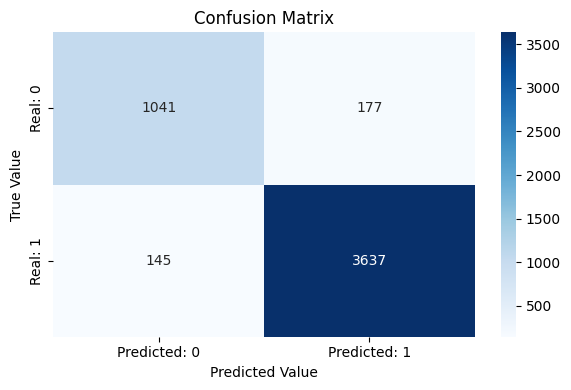

In [4]:
# X = df.drop(columns=['soil_type','radius','pos_x','pos_y','presence'])
X = df.drop(columns=['radius','pos_x','pos_y','presence'])


X = scaler.fit_transform(X)

Y = df['presence']

y1 = cross_val_predict(hgb, X, Y,cv=cv, method='predict')
y1 = pd.DataFrame(y1).rename(columns={0:'presence_pred'})

print_results(reg=False,y_test=Y,y_pred=y1)

matriz_c = confusion_matrix(Y,y1)
plt.figure(figsize=(6, 4))
sns.heatmap(matriz_c, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Predicted: 0', 'Predicted: 1'], 
            yticklabels=['Real: 0', 'Real: 1'])

plt.title('Confusion Matrix')
plt.ylabel('True Value')
plt.xlabel('Predicted Value')
plt.tight_layout()
plt.show()

Previsão do tipo de solo?

In [5]:
# Y = df['soil_type'][y1['presence_pred']==1]

# print(Y.value_counts())

Predição da posição lateral via Gradient Boosting Regressor

In [ ]:
# X2 = X[y1['presence_pred']==1]
X = pd.DataFrame(X)
X2 = pd.concat((X,y1),axis=1)
Y2 = df['pos_x']#[y1['presence_pred']==1]


FEATURE IMPORTANCE

COMPARAR MODELOS PARA ENRIQUECER RESULTADOS

y2 = cross_val_predict(model_xg, X2, Y2,cv=cv, method='predict')
y2 = pd.DataFrame(y2)
y2 = y2.rename(columns={0:'pos_x_pred'})

print('Posição em x:')
print_results(reg=True,y_test=Y2,y_pred=y2)

Posição em x:
R²: 0.9283464070791615
RMSE: 0.014784280998258958
MAE: 0.009897751102305556


Predição da posição vertical via XGBoost

In [7]:
# X2 = pd.DataFrame(X2)

X2 = df.drop(columns=['soil_type','radius','pos_x','pos_y','presence'])

X2 = scaler.fit_transform(X2)

X2 = pd.DataFrame(X2)

X3 = pd.concat((X2.reset_index(drop=True),y2),axis=1)
Y3 = df['pos_y']#[y1['presence_pred']==1].reset_index(drop=True)

y3 = cross_val_predict(model_xg, X3, Y3,cv=cv, method='predict')
y3 = pd.DataFrame(y3).rename(columns={0:'pos_y_pred'})

print_results(reg=True,y_test=Y3,y_pred=y3)

R²: 0.8013523989470468
RMSE: 0.006760165537371368
MAE: 0.0053061780263342325


Predição do raio via XGBoost

In [8]:
# X4 = pd.read_csv('databasev4_2.csv')

X4 = pd.concat((X3,y3),axis=1)

features_raio = [
    'larg_x_50',
    'larg_x_25',
    'larg_t_50',
    'larg_t_25',
    'a_max',
    'x_pico_env',
    't_pico_env',
    'rms_banda',
    'frac_energia_banda',
    'freq_peak_apex',
    'freq_bw_apex',
    'score_fit',
    'rms_global',
    'kurtosis_global'
]

# X4 = X4[features_raio]

# X4 = pd.concat((X4,y1,y2,y3),axis=1)
# X4 =  pd.read_csv('features_raio.csv')

Y4 = df['radius']#[y1['presence_pred']==1].reset_index(drop=True)
y4 = cross_val_predict(model_xg, X4, Y4,cv=cv, method='predict')
y4 = pd.DataFrame(y4)
y4 = y4.rename(columns={0:'radius_pred'})

print('Raio:')
print_results(reg=True,y_test=Y4,y_pred=y4)

# # APLICAR CNN!!!!
# # R2 AJUSTADO, VERIFICAR ROI

Raio:
R²: 0.20559581492863865
RMSE: 0.0037994476724196352
MAE: 0.0031909758375838395


Predição do raio via SVRM

In [9]:
# X4 = pd.concat((X3,y3),axis=1)
# Y4 = df['radius'][y1['presence_pred']==1].reset_index(drop=True)

# y4 = cross_val_predict(svrm, X4, Y4,cv=cv, method='predict')
# y4 = pd.DataFrame(y4)
# y4 = y4.rename(columns={0:'radius_pred'})

# print('Raio:')
# print_results(reg=True,y_test=Y4,y_pred=y4)

# from sklearn.model_selection import GridSearchCV

# param_grid = {
#     'svr__C': [0.1, 1, 10, 100, 1000],
#     'svr__epsilon': [0.01, 0.1, 0.2, 0.5, 1],
#     'svr__gamma': ['scale', 'auto', 0.001, 0.01, 0.1, 1]
# }

# grid = GridSearchCV(
#     estimator=model,
#     param_grid=param_grid,
#     cv=5,
#     scoring='neg_mean_squared_error',
#     n_jobs=-1,
#     verbose=1
# )

# grid.fit(X_train, y_train)

# print("Melhores parâmetros:", grid.best_params_)

# best_model = grid.best_estimator_

In [ ]:
mlp = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),

    ('scaler', StandardScaler()),

    ('model', MLPRegressor(
        hidden_layer_sizes=(128, 64, 32),
        activation='relu',
        solver='adam',
        alpha=0.001,
        learning_rate_init=0.001,
        max_iter=2000,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=30,
        random_state=42
    ))
])

# Treinamento
mlp.fit(X_train, y_train)

# Predição
y_pred = mlp.predict(X_test)

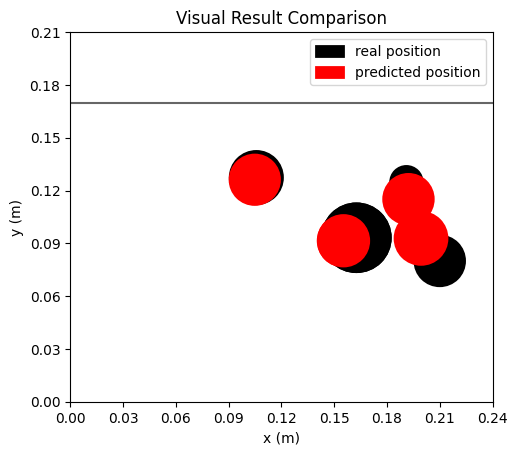

In [10]:
predictions = pd.concat((y2,y3,y4),axis=1)
predictions = predictions[y1['presence_pred']==1].reset_index(drop=True)
real_values = df[['pos_x','pos_y','radius']][y1['presence_pred']==1].reset_index(drop=True)
# display(predictions)
# display(real_values)

pos_x_pred = predictions['pos_x_pred']
pos_y_pred = predictions['pos_y_pred']
radius_pred = predictions['radius_pred']

pos_x = real_values['pos_x']
pos_y = real_values['pos_y']
radius = real_values['radius']


X = pd.DataFrame(X)
idx_col = X[y1['presence_pred']==1].index


fig, ax = plt.subplots()

circulo_pred = plt.Circle((pos_x_pred[0], pos_y_pred[0]), radius_pred[0], color='red', fill=True, linewidth=2,label='predicted position')
# plt.scatter(pos_x_pred[i], pos_y_pred[i],color='red',s=10,label='predicted position')

circulo_real = plt.Circle((pos_x[0], pos_y[0]), radius[0], color='black', fill=True, linewidth=2,label='real position')
# plt.scatter(pos_x[i], pos_y[i],color='black',s=10,label='real position')

ax.add_patch(circulo_real)
ax.add_patch(circulo_pred)

for i in range(4):
    # Círculo: centro (x,y) e raio r


    circulo_pred = plt.Circle((pos_x_pred[i], pos_y_pred[i]), radius_pred[i], color='red', fill=True, linewidth=2)#,label='predicted position')
    # plt.scatter(pos_x_pred[i], pos_y_pred[i],color='red',s=10,label='predicted position')

    circulo_real = plt.Circle((pos_x[i], pos_y[i]), radius[i], color='black', fill=True, linewidth=2)#,label='real position')
    # plt.scatter(pos_x[i], pos_y[i],color='black',s=10,label='real position')

    ax.add_patch(circulo_real)
    ax.add_patch(circulo_pred)

ax.set_title(f'Visual Result Comparison') # - B-scan {idx_col[i]}')


ax.set_xlim(0, 0.24)
ax.set_ylim(0, 0.21)
ax.set_aspect('equal')
ax.set_xticks(np.arange(0,0.241,0.03))
ax.set_yticks(np.arange(0,0.211,0.03))
ax.set_xlabel(r"x (m)")
ax.set_ylabel(r"y (m)")
# ax.axvline(x=0.08,color='black',ls='--',alpha=0.2,ymax=0.17/0.21)
# ax.axvline(x=0.2,color='black',ls='--',alpha=0.2,ymax=0.17/0.21)
ax.axhline(y=0.17,color='black',alpha=0.6)

# ax.axvline(x=pos_x_pred[i],color='red',ls='--',alpha=0.6,ymax=pos_y_pred[i]/0.21)
# ax.axvline(x=pos_x[i],color='black',ls='--',alpha=0.6,ymax=pos_y[i]/0.21)
# ax.axhline(y=pos_y_pred[i],color='red',ls='--',alpha=0.6,xmax=pos_x_pred[i]/0.24)
# ax.axhline(y=pos_y[i],color='black',ls='--',alpha=0.6,xmax=pos_x[i]/0.24)

ax.legend()
plt.show()

COM ESSES VALORES PREVISTOS EM MÃO, DÁ PRA IDENTIFICAR O TIPO DE SOLO??